In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

sns.set_style('whitegrid')
%matplotlib inline

train = pd.read_csv("../data/raw/train.csv")
test = pd.read_csv("../data/raw/test.csv")

print("Train shape:", train.shape)
print("Test shape:",test.shape)

Train shape: (891, 12)
Test shape: (418, 11)


In [2]:
X = train.drop("Survived",axis=1) #X=Features
y = train["Survived"]   #y=Target

print("X shape:",X.shape)
print("y shape:",y.shape)

X shape: (891, 11)
y shape: (891,)


In [3]:
print("Features:")
print(X.columns.tolist())

print("\nTarget:")
print(y.name)

Features:
['PassengerId', 'Pclass', 'Name', 'Sex', 'Age', 'SibSp', 'Parch', 'Ticket', 'Fare', 'Cabin', 'Embarked']

Target:
Survived


In [4]:
print("Sex:", X["Sex"].unique()) #Returns an array of all distinct, non-duplicate values present in the Sex column
print("Embarked:", X["Embarked"].unique())
print("Pclass:", X["Pclass"].unique())

Sex: ['male' 'female']
Embarked: ['S' 'C' 'Q' nan]
Pclass: [3 1 2]


In [5]:
# Check high cardinality columns (Cardinality = number of unique values in a feature.)
print("Name unique:", X["Name"].nunique())
print("Ticket unique:", X["Ticket"].nunique())
print("Cabin unique:", X["Cabin"].nunique())

Name unique: 891
Ticket unique: 681
Cabin unique: 147


In [6]:
# Create FamilySize
X["FamilySize"] = X["SibSp"] + X["Parch"] + 1

# Create IsAlone
X["IsAlone"] = (X["FamilySize"] == 1).astype(int)

# Extract Title from Name
X["Title"] = X["Name"].str.extract(r",\s*([^.]*)\.")

# Group less common titles
X["Title"] = X["Title"].where(
    X["Title"].isin(["Mr", "Miss", "Mrs", "Master"]),
    "Rare"
)

In [7]:
X[[
    "SibSp",
    "Parch",
    "FamilySize",
    "IsAlone",
    "Name",
    "Title"
]].head(10)

,SibSp,Parch,FamilySize,IsAlone,Name,Title
0,1,0,2,0,"Braund, Mr. Owen Harris",Mr
1,1,0,2,0,"Cumings, Mrs. John Bradley (Florence Briggs Th...",Mrs
2,0,0,1,1,"Heikkinen, Miss. Laina",Miss
3,1,0,2,0,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",Mrs
4,0,0,1,1,"Allen, Mr. William Henry",Mr
5,0,0,1,1,"Moran, Mr. James",Mr
6,0,0,1,1,"McCarthy, Mr. Timothy J",Mr
7,3,1,5,0,"Palsson, Master. Gosta Leonard",Master
8,0,2,3,0,"Johnson, Mrs. Oscar W (Elisabeth Vilhelmina Berg)",Mrs
9,1,0,2,0,"Nasser, Mrs. Nicholas (Adele Achem)",Mrs


In [8]:
# handling missing value age
print("Missing values in X:")
print(X.isnull().sum().sort_values(ascending=False)) #X.isnull() identifies missing values (NaN).

print("\nMissing percentage in X:")
print(
    (X.isnull().mean() * 100)
    .sort_values(ascending=False)
    .round(2)
)

Missing values in X:
Cabin          687
Age            177
Embarked         2
PassengerId      0
Pclass           0
Name             0
Sex              0
SibSp            0
Parch            0
Ticket           0
Fare             0
FamilySize       0
IsAlone          0
Title            0
dtype: int64

Missing percentage in X:
Cabin          77.10
Age            19.87
Embarked        0.22
PassengerId     0.00
Pclass          0.00
Name            0.00
Sex             0.00
SibSp           0.00
Parch           0.00
Ticket          0.00
Fare            0.00
FamilySize      0.00
IsAlone         0.00
Title           0.00
dtype: float64


Mean age: 29.69911764705882
Median age: 28.0


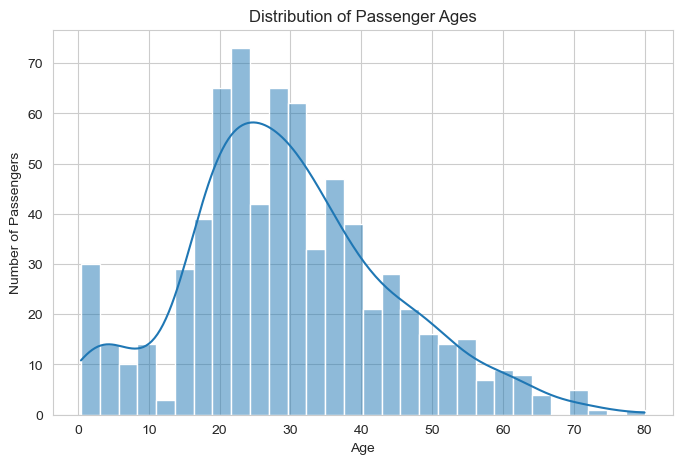

In [9]:
#Compare mean and median age
print("Mean age:", X["Age"].mean())
print("Median age:", X["Age"].median())

plt.figure(figsize=(8, 5))

sns.histplot(
    data=X,
    x="Age",
    bins=30,
    kde=True
)

plt.title("Distribution of Passenger Ages")
plt.xlabel("Age")
plt.ylabel("Number of Passengers")

plt.show()

In [10]:
#Test median imputation without changing X
age_median = X["Age"].median()

X_age_demo = X[["Age"]].copy() #contains the original Age column and a new Age_Imputed column.

X_age_demo["Age_Imputed"] = X_age_demo["Age"].fillna(age_median)

print("Missing ages before:", X_age_demo["Age"].isnull().sum())
print("Missing ages after:", X_age_demo["Age_Imputed"].isnull().sum())

print("\nMedian used:", age_median)
#Missing ages in Age_Imputed are replaced with the median.
#The original Age column still contains its missing values, allowing us to compare both versions.

Missing ages before: 177
Missing ages after: 0

Median used: 28.0


In [11]:
#Compare age by title and passenger class
age_by_title = X.groupby("Title")["Age"].agg(
    ["count", "median", "mean"]
).round(2)

print(age_by_title)

        count  median   mean
Title                       
Master     36     3.5   4.57
Miss      146    21.0  21.77
Mr        398    30.0  32.37
Mrs       108    35.0  35.90
Rare       26    44.5  42.38


In [12]:
# Compare age by passenger class
age_by_class = X.groupby("Pclass")["Age"].agg(
    ["count", "median", "mean"]
).round(2)

print(age_by_class)

        count  median   mean
Pclass                      
1         186    37.0  38.23
2         173    29.0  29.88
3         355    24.0  25.14


In [13]:
#For our first baseline preprocessing pipeline,we use  median imputation because it is simple, robust to outliers, and provides a useful benchmark.
from sklearn.impute import SimpleImputer
age_imputer = SimpleImputer(strategy="median")
#strategy="median" tells it to calculate the median from the data passed to .fit().
#age_imputer stores the imputation object; it has not changed X yet.

In [14]:
from sklearn.model_selection import train_test_split

X = train.drop(columns=["Survived"])
y = train["Survived"]

X_train, X_valid, y_train, y_valid = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("X_train:", X_train.shape)
print("X_valid:", X_valid.shape)
print("y_train:", y_train.shape)
print("y_valid:", y_valid.shape)

X_train: (712, 11)
X_valid: (179, 11)
y_train: (712,)
y_valid: (179,)


In [15]:
print("Training survival proportions:")
print(y_train.value_counts(normalize=True).round(3))

print("\nValidation survival proportions:")
print(y_valid.value_counts(normalize=True).round(3))

Training survival proportions:
Survived
0    0.617
1    0.383
Name: proportion, dtype: float64

Validation survival proportions:
Survived
0    0.615
1    0.385
Name: proportion, dtype: float64


In [16]:
#Create the feature-engineering function
def create_features(df):

    df = df.copy()

    # 1. Create FamilySize
    df["FamilySize"] = df["SibSp"] + df["Parch"] + 1

    # 2. Create IsAlone
    df["IsAlone"] = (df["FamilySize"] == 1).astype(int)

    # 3. Extract Title from Name
    df["Title"] = df["Name"].str.extract(r",\s*([^.]*)\.")

    # 4. Group rare titles
    df["Title"] = df["Title"].where(
        df["Title"].isin(["Mr", "Miss", "Mrs", "Master"]),
        "Rare"
    )

    return df

In [17]:
test = pd.read_csv("../data/raw/test.csv")

In [18]:
X_train_fe = create_features(X_train)

X_valid_fe = create_features(X_valid)

test_fe = create_features(test)

In [19]:
columns_to_check = [
    "SibSp",
    "Parch",
    "FamilySize",
    "IsAlone",
    "Name",
    "Title"
]

X_train_fe[columns_to_check].head(10)

,SibSp,Parch,FamilySize,IsAlone,Name,Title
692,0,0,1,1,"Lam, Mr. Ali",Mr
481,0,0,1,1,"Frost, Mr. Anthony Wood ""Archie""",Mr
527,0,0,1,1,"Farthing, Mr. John",Mr
855,0,1,2,0,"Aks, Mrs. Sam (Leah Rosen)",Mrs
801,1,1,3,0,"Collyer, Mrs. Harvey (Charlotte Annie Tate)",Mrs
652,0,0,1,1,"Kalvik, Mr. Johannes Halvorsen",Mr
509,0,0,1,1,"Lang, Mr. Fang",Mr
557,0,0,1,1,"Robbins, Mr. Victor",Mr
828,0,0,1,1,"McCormack, Mr. Thomas Joseph",Mr
18,1,0,2,0,"Vander Planke, Mrs. Julius (Emelia Maria Vande...",Mrs


In [20]:
print("Training:", X_train_fe.shape)
print("Validation:", X_valid_fe.shape)
print("Kaggle test:", test_fe.shape)

Training: (712, 14)
Validation: (179, 14)
Kaggle test: (418, 14)


In [21]:
numerical_features = [
    "Pclass",
    "Age",
    "SibSp",
    "Parch",
    "Fare",
    "FamilySize",
    "IsAlone"
]

categorical_features = [
    "Sex",
    "Embarked",
    "Title"
]

In [22]:
print("Numerical features:")
print(numerical_features)

print("\nCategorical features:")
print(categorical_features)

Numerical features:
['Pclass', 'Age', 'SibSp', 'Parch', 'Fare', 'FamilySize', 'IsAlone']

Categorical features:
['Sex', 'Embarked', 'Title']


In [23]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

In [24]:
numerical_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

In [25]:
categorical_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

In [26]:
preprocessor = ColumnTransformer(
    transformers=[
        ("num", numerical_pipeline, numerical_features),
        ("cat", categorical_pipeline, categorical_features)
    ]
)

In [27]:
X_train_processed = preprocessor.fit_transform(X_train_fe)

X_valid_processed = preprocessor.transform(X_valid_fe)

test_processed = preprocessor.transform(test_fe)

In [28]:
print("Training processed shape:", X_train_processed.shape)
print("Validation processed shape:", X_valid_processed.shape)
print("Test processed shape:", test_processed.shape)

Training processed shape: (712, 17)
Validation processed shape: (179, 17)
Test processed shape: (418, 17)


In [29]:
feature_names = preprocessor.get_feature_names_out()

print("Total processed features:", len(feature_names))
print("\nProcessed feature names:")

for feature in feature_names:
    print(feature)

Total processed features: 17

Processed feature names:
num__Pclass
num__Age
num__SibSp
num__Parch
num__Fare
num__FamilySize
num__IsAlone
cat__Sex_female
cat__Sex_male
cat__Embarked_C
cat__Embarked_Q
cat__Embarked_S
cat__Title_Master
cat__Title_Miss
cat__Title_Mr
cat__Title_Mrs
cat__Title_Rare


In [30]:
X_train_processed_df = pd.DataFrame(
    X_train_processed.toarray()
    if hasattr(X_train_processed, "toarray")
    else X_train_processed,
    columns=feature_names
)

X_train_processed_df.head()

,num__Pclass,num__Age,num__SibSp,num__Parch,num__Fare,num__FamilySize,num__IsAlone,cat__Sex_female,cat__Sex_male,cat__Embarked_C,cat__Embarked_Q,cat__Embarked_S,cat__Title_Master,cat__Title_Miss,cat__Title_Mr,cat__Title_Mrs,cat__Title_Rare
0,0.829568,-0.081135,-0.465084,-0.466183,0.513812,-0.556339,0.800346,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0
1,-0.370945,-0.081135,-0.465084,-0.466183,-0.662563,-0.556339,0.800346,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0
2,-1.571457,-0.081135,-0.465084,-0.466183,3.955399,-0.556339,0.800346,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0
3,0.829568,-0.887827,-0.465084,0.727782,-0.467874,0.073412,-1.249460,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0
4,-0.370945,0.110934,0.478335,0.727782,-0.115977,0.703162,-1.249460,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0


In [31]:
from sklearn.linear_model import LogisticRegression

In [32]:
logistic_model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

print(logistic_model)

LogisticRegression(max_iter=1000, random_state=42)


In [33]:
logistic_model.fit(X_train_processed, y_train)

print("Model training completed!")

Model training completed!


In [34]:
y_pred = logistic_model.predict(X_valid_processed)

print("First 20 predictions:")
print(y_pred[:20])

print("\nFirst 20 actual values:")
print(y_valid.iloc[:20].values)

First 20 predictions:
[0 0 0 0 1 1 1 0 0 0 0 0 1 0 0 0 0 0 0 1]

First 20 actual values:
[0 0 1 0 1 1 1 0 0 0 0 0 1 0 0 0 0 0 0 1]


In [35]:
from sklearn.metrics import accuracy_score

accuracy = accuracy_score(y_valid, y_pred)

print(f"Validation Accuracy: {accuracy:.4f}")
print(f"Validation Accuracy: {accuracy * 100:.2f}%")

Validation Accuracy: 0.8436
Validation Accuracy: 84.36%


In [36]:
from sklearn.metrics import classification_report

print(classification_report(y_valid, y_pred))

              precision    recall  f1-score   support

           0       0.85      0.90      0.88       110
           1       0.83      0.75      0.79        69

    accuracy                           0.84       179
   macro avg       0.84      0.83      0.83       179
weighted avg       0.84      0.84      0.84       179



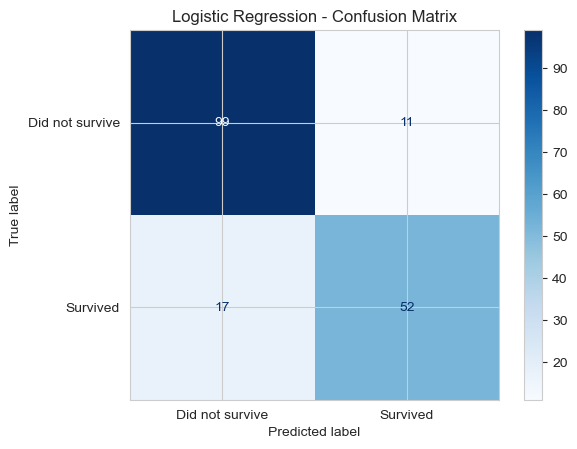

In [37]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

cm = confusion_matrix(y_valid, y_pred)

display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Did not survive", "Survived"]
)

display.plot(cmap="Blues")
plt.title("Logistic Regression - Confusion Matrix")
plt.show()

In [38]:
# Why Random Forest?
# Logistic Regression learns a relatively simple linear relationship between features and the target.

#Random Forest works differently:
#1. It creates multiple decision trees.
#2. Each tree learns different patterns from sampled training data and features.
#3. Each tree makes a prediction.
#4. The forest combines their predictions using majority voting.
#For Titanic, it may capture relationships such as:
#- Survival patterns differing across passenger classes.
#- Age having different effects depending on sex.
#- Family size interacting with other features. 

In [39]:
from sklearn.ensemble import RandomForestClassifier

In [40]:
random_forest_model = RandomForestClassifier(
    n_estimators=200,
    max_depth=5,
    min_samples_split=5,
    min_samples_leaf=2,
    random_state=42,
    n_jobs=-1
)

print(random_forest_model)

RandomForestClassifier(max_depth=5, min_samples_leaf=2, min_samples_split=5,
                       n_estimators=200, n_jobs=-1, random_state=42)


In [41]:
random_forest_model.fit(X_train_processed, y_train)

print("Random Forest training completed!")

Random Forest training completed!


In [42]:
rf_predictions = random_forest_model.predict(X_valid_processed)

print("First 20 predictions:")
print(rf_predictions[:20])

print("\nFirst 20 actual values:")
print(y_valid.iloc[:20].values)

First 20 predictions:
[0 0 0 0 1 1 1 0 0 0 0 0 1 0 0 0 0 0 0 1]

First 20 actual values:
[0 0 1 0 1 1 1 0 0 0 0 0 1 0 0 0 0 0 0 1]


In [43]:
from sklearn.metrics import accuracy_score, classification_report

rf_accuracy = accuracy_score(y_valid, rf_predictions)

print(f"Random Forest Accuracy: {rf_accuracy:.4f}")
print(f"Random Forest Accuracy: {rf_accuracy * 100:.2f}%")

print("\nClassification Report:")
print(classification_report(y_valid, rf_predictions))

Random Forest Accuracy: 0.8324
Random Forest Accuracy: 83.24%

Classification Report:
              precision    recall  f1-score   support

           0       0.84      0.89      0.87       110
           1       0.81      0.74      0.77        69

    accuracy                           0.83       179
   macro avg       0.83      0.82      0.82       179
weighted avg       0.83      0.83      0.83       179



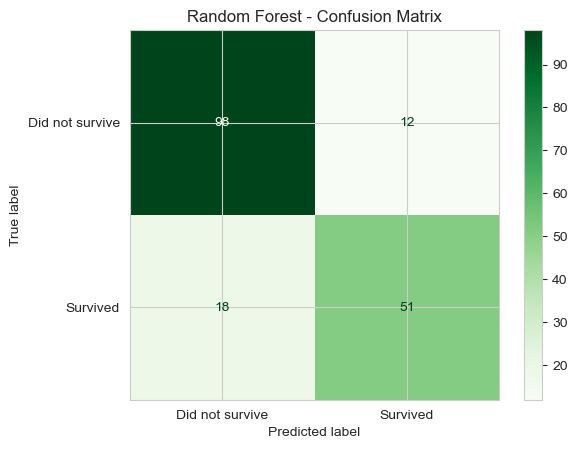

In [44]:
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

ConfusionMatrixDisplay.from_predictions(
    y_valid,
    rf_predictions,
    display_labels=["Did not survive", "Survived"],
    cmap="Greens"
)

plt.title("Random Forest - Confusion Matrix")
plt.show()

In [45]:
model_comparison = pd.DataFrame({
    "Model": ["Logistic Regression", "Random Forest"],
    "Accuracy": [accuracy, rf_accuracy]
})

model_comparison["Accuracy (%)"] = (
    model_comparison["Accuracy"] * 100
).round(2)

model_comparison

,Model,Accuracy,Accuracy (%)
0,Logistic Regression,0.843575,84.36
1,Random Forest,0.832402,83.24


In [46]:
feature_importance = pd.DataFrame({
    "Feature": feature_names,
    "Importance": random_forest_model.feature_importances_
})

feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

feature_importance

,Feature,Importance
8,cat__Sex_male,0.189899
14,cat__Title_Mr,0.175688
7,cat__Sex_female,0.130603
4,num__Fare,0.104604
0,num__Pclass,0.097989
1,num__Age,0.066253
5,num__FamilySize,0.055412
15,cat__Title_Mrs,0.049655
13,cat__Title_Miss,0.038868
2,num__SibSp,0.025488


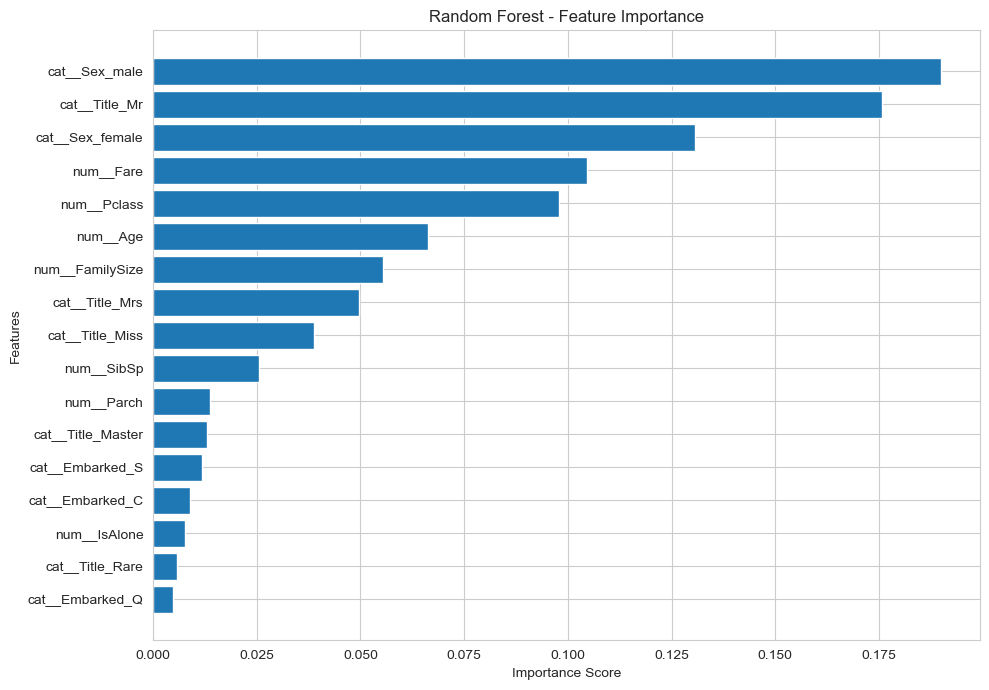

In [47]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 7))

plt.barh(
    feature_importance["Feature"],
    feature_importance["Importance"]
)

plt.gca().invert_yaxis()

plt.xlabel("Importance Score")
plt.ylabel("Features")
plt.title("Random Forest - Feature Importance")

plt.tight_layout()
plt.show()

In [48]:
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.ensemble import RandomForestClassifier

In [49]:
param_grid = {
    "n_estimators": [100, 200, 300],
    "max_depth": [3, 5, 7, None],
    "min_samples_split": [2, 5, 10],
    "min_samples_leaf": [1, 2, 4]
}

In [50]:
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

In [51]:
grid_search = GridSearchCV(
    estimator=RandomForestClassifier(random_state=42, n_jobs=-1),
    param_grid=param_grid,
    scoring="accuracy",
    cv=cv,
    n_jobs=-1,
    verbose=1
)

In [52]:
grid_search.fit(X_train_processed, y_train)

print("Tuning completed!")

Fitting 5 folds for each of 108 candidates, totalling 540 fits
Tuning completed!


In [53]:
print("Best Parameters:")
print(grid_search.best_params_)

print("\nBest Cross-Validation Accuracy:")
print(grid_search.best_score_)

Best Parameters:
{'max_depth': 3, 'min_samples_leaf': 1, 'min_samples_split': 10, 'n_estimators': 200}

Best Cross-Validation Accuracy:
0.830089628681178


In [54]:
best_rf_model = grid_search.best_estimator_

tuned_predictions = best_rf_model.predict(X_valid_processed)

tuned_accuracy = accuracy_score(y_valid, tuned_predictions)

print(f"Tuned Random Forest Accuracy: {tuned_accuracy:.4f}")
print(f"Tuned Random Forest Accuracy: {tuned_accuracy * 100:.2f}%")

print("\nClassification Report:")
print(classification_report(y_valid, tuned_predictions))

Tuned Random Forest Accuracy: 0.8045
Tuned Random Forest Accuracy: 80.45%

Classification Report:
              precision    recall  f1-score   support

           0       0.81      0.89      0.85       110
           1       0.79      0.67      0.72        69

    accuracy                           0.80       179
   macro avg       0.80      0.78      0.79       179
weighted avg       0.80      0.80      0.80       179



In [55]:
comparison = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Random Forest",
        "Tuned Random Forest"
    ],
    "Accuracy": [
        accuracy,
        rf_accuracy,
        tuned_accuracy
    ]
})

comparison["Accuracy (%)"] = (
    comparison["Accuracy"] * 100
).round(2)

comparison = comparison.sort_values(
    by="Accuracy",
    ascending=False
)

comparison

,Model,Accuracy,Accuracy (%)
0,Logistic Regression,0.843575,84.36
1,Random Forest,0.832402,83.24
2,Tuned Random Forest,0.804469,80.45


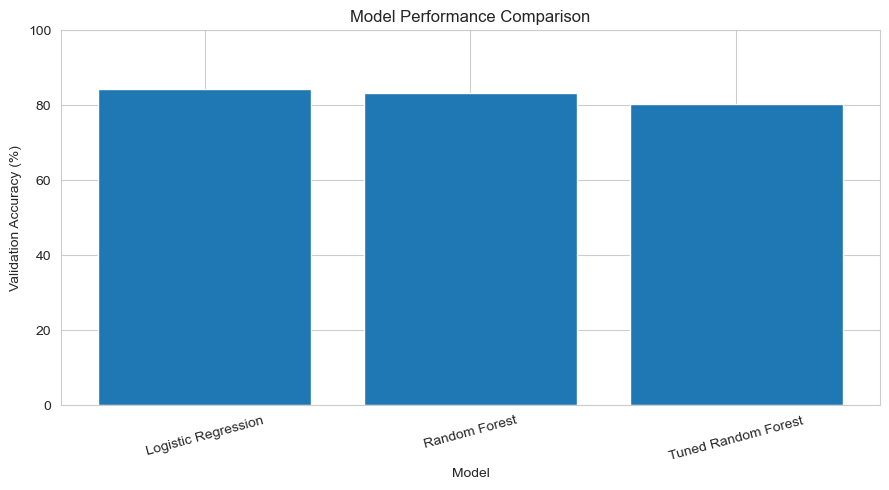

In [56]:
plt.figure(figsize=(9, 5))

plt.bar(
    comparison["Model"],
    comparison["Accuracy (%)"]
)

plt.ylabel("Validation Accuracy (%)")
plt.xlabel("Model")
plt.title("Model Performance Comparison")
plt.ylim(0, 100)
plt.xticks(rotation=15)

plt.tight_layout()
plt.show()

In [57]:
final_model = best_rf_model

print("Final model selected: Tuned Random Forest")

Final model selected: Tuned Random Forest


In [58]:
test_predictions = final_model.predict(test_processed)

print("Total predictions:", len(test_predictions))
print("First 20 predictions:")
print(test_predictions[:20])

Total predictions: 418
First 20 predictions:
[0 1 0 0 1 0 1 0 1 0 0 0 1 0 1 1 0 0 1 1]


In [59]:
submission = pd.DataFrame({
    "PassengerId": test["PassengerId"],
    "Survived": test_predictions
})

submission.head()

,PassengerId,Survived
0,892,0
1,893,1
2,894,0
3,895,0
4,896,1


In [60]:
print("Submission shape:", submission.shape)

print("\nMissing values:")
print(submission.isnull().sum())

print("\nPrediction distribution:")
print(submission["Survived"].value_counts())

print("\nColumn names:")
print(submission.columns.tolist())

Submission shape: (418, 2)

Missing values:
PassengerId    0
Survived       0
dtype: int64

Prediction distribution:
Survived
0    263
1    155
Name: count, dtype: int64

Column names:
['PassengerId', 'Survived']


In [61]:
from pathlib import Path

# Create outputs folder if it does not exist
output_dir = Path("../outputs")
output_dir.mkdir(parents=True, exist_ok=True)

# Save submission
submission_path = output_dir / "titanic_submission.csv"

submission.to_csv(submission_path, index=False)

print("Submission saved to:", submission_path.resolve())

Submission saved to: C:\Users\Roshan Regmi\OneDrive\Desktop\ml_prj1\titanic_survival_prediction\outputs\titanic_submission.csv


In [ ]:
#Compare the three models with cross-validation on all 891 rows
from sklearn.model_selection import cross_val_score

# All 891 raw training rows (X from cell 13) with engineered features added
X_full_fe = create_features(X)

models = {
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=42),
    "Random Forest": RandomForestClassifier(
        n_estimators=200, max_depth=5, min_samples_split=5,
        min_samples_leaf=2, random_state=42, n_jobs=-1
    ),
    "Tuned Random Forest": RandomForestClassifier(
        **grid_search.best_params_, random_state=42, n_jobs=-1
    )
}

cv_results = {}

for name, model in models.items():
    full_pipeline = Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("model", model)
    ])

    scores = cross_val_score(
        full_pipeline,
        X_full_fe,
        y,
        cv=cv,
        scoring="accuracy"
    )

    cv_results[name] = scores
    print(f"{name}: mean = {scores.mean():.4f}, std = {scores.std():.4f}")
    print("   fold scores:", scores.round(3))

Logistic Regression: mean = 0.8283, std = 0.0078
   fold scores: [0.838 0.815 0.826 0.831 0.831]
Random Forest: mean = 0.8316, std = 0.0071
   fold scores: [0.832 0.82  0.831 0.831 0.843]
Tuned Random Forest: mean = 0.8260, std = 0.0148
   fold scores: [0.838 0.815 0.82  0.809 0.848]


In [ ]:
#All three models sit within 0.6 points of each other (82.6–83.2%), and their fold scores overlap heavily.
#For example, fold 1 is 0.838 for both Logistic Regression and Tuned Random Forest.

#Tuned Random Forest has about twice the fold-to-fold spread (std 0.0148 vs about 0.007). 
# It ranges from 0.809 to 0.848, so tuning bought you instability, not accuracy.

# This is the winner’s curse. Grid search tried 108 settings and kept the best one, so part of its 0.830 score was luck in how that setting happened to fit those folds. 
# Fresh evaluation brings it back down to 0.826.

#The models are effectively tied, so the fair way to choose is a rule written before looking: pick the highest CV mean. 
# That gives Random Forest, a nominal win rather than proof it’s better.

In [63]:
#: pick the model by CV, then refit on all 891 rows
from sklearn.base import clone

# Summarise cross-validation results
cv_summary = pd.DataFrame({
    "Model": list(cv_results.keys()),
    "CV Mean": [scores.mean() for scores in cv_results.values()],
    "CV Std": [scores.std() for scores in cv_results.values()]
})

cv_summary["CV Mean (%)"] = (cv_summary["CV Mean"] * 100).round(2)

cv_summary = cv_summary.sort_values(
    by="CV Mean",
    ascending=False
).reset_index(drop=True)

print(cv_summary)

# Select the model with the highest CV mean
best_model_name = cv_summary.loc[0, "Model"]
print("\nSelected by CV:", best_model_name)

# Build a fresh pipeline and train it on ALL training rows
final_pipeline = Pipeline(steps=[
    ("preprocessor", clone(preprocessor)),
    ("model", clone(models[best_model_name]))
])

final_pipeline.fit(X_full_fe, y)

print("Final pipeline trained on:", X_full_fe.shape[0], "rows")

                 Model   CV Mean    CV Std  CV Mean (%)
0        Random Forest  0.831649  0.007116        83.16
1  Logistic Regression  0.828272  0.007841        82.83
2  Tuned Random Forest  0.826025  0.014793        82.60

Selected by CV: Random Forest
Final pipeline trained on: 891 rows


In [64]:
#predict on the test set, sanity-check, and save v2
from pathlib import Path

# Predict with the final pipeline (it preprocesses test_fe by itself)
final_predictions = final_pipeline.predict(test_fe)

submission_v2 = pd.DataFrame({
    "PassengerId": test["PassengerId"],
    "Survived": final_predictions
})

# Sanity checks
print("Submission shape:", submission_v2.shape)
print("Column names:", submission_v2.columns.tolist())
print("Missing values:", submission_v2.isnull().sum().sum())
print("Unique PassengerIds:", submission_v2["PassengerId"].nunique())
print("Values in Survived:", sorted(submission_v2["Survived"].unique().tolist()))

print("\nPrediction distribution:")
print(submission_v2["Survived"].value_counts())
print("Predicted survival rate: {:.1f}% (training data: 38.4%)".format(
    submission_v2["Survived"].mean() * 100
))

# Compare with the first submission file saved in cell 60
output_dir = Path("../outputs")
submission_v1 = pd.read_csv(output_dir / "titanic_submission.csv")

n_different = (submission_v1["Survived"] != submission_v2["Survived"]).sum()
print("\nPredictions that differ from submission v1:", n_different, "of", len(submission_v2))

# Save v2 (new file name, v1 stays untouched)
submission_v2_path = output_dir / "titanic_submission_v2.csv"
submission_v2.to_csv(submission_v2_path, index=False)
print("Saved to:", submission_v2_path.resolve())

Submission shape: (418, 2)
Column names: ['PassengerId', 'Survived']
Missing values: 0
Unique PassengerIds: 418
Values in Survived: [0, 1]

Prediction distribution:
Survived
0    254
1    164
Name: count, dtype: int64
Predicted survival rate: 39.2% (training data: 38.4%)

Predictions that differ from submission v1: 11 of 418
Saved to: C:\Users\Roshan Regmi\OneDrive\Desktop\ml_prj1\titanic_survival_prediction\outputs\titanic_submission_v2.csv
